# Dự án mini: Dự đoán khách hàng đăng ký tiền gửi có kỳ hạn (Bank Marketing)
**Môn:** Phân tích dữ liệu và trí tuệ nhân tạo

**Bài toán:** Một ngân hàng Bồ Đào Nha gọi điện tiếp thị tiền gửi có kỳ hạn. Cần dự đoán khách hàng nào sẽ đồng ý (`y = yes`) để ưu tiên gọi đúng người, giảm chi phí tiếp thị.

**Dữ liệu:** `bank-full.csv` (UCI Bank Marketing) – 45.211 dòng, 16 đặc trưng, biến mục tiêu `y`.

**Tác giả:** Sérgio Moro, Paulo Cortez, P. Rita.

In [11]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Đọc dữ liệu và khám phá ban đầu
File dùng dấu chấm phẩy `;` làm dấu phân cách.

In [12]:
df = pd.read_csv("bank-full.csv", sep=";")
print("Kích thước:", df.shape)
df.head()

Kích thước: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [13]:
df.info()
print("\nGiá trị thiếu (NaN):", df.isna().sum().sum())
print("Dòng trùng lặp:", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

Giá trị thiếu (NaN): 0
Dòng trùng lặp: 0


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


**Nhận xét:** không có NaN và không có dòng trùng. Tuy nhiên nhiều cột phân loại chứa giá trị `"unknown"` (thực chất là dữ liệu thiếu được mã hóa dạng chữ). Cột `pdays = -1` nghĩa là khách chưa từng được liên hệ ở chiến dịch trước.

In [14]:
unk = (df.select_dtypes(exclude="number") == "unknown").mean().mul(100).round(1)
print("Tỷ lệ 'unknown' (%) theo cột:")
print(unk[unk > 0].sort_values(ascending=False))
print("\npdays = -1 (chưa liên hệ trước đó):", round((df.pdays == -1).mean()*100, 1), "%")

Tỷ lệ 'unknown' (%) theo cột:
poutcome     81.7
contact      28.8
education     4.1
job           0.6
dtype: float64

pdays = -1 (chưa liên hệ trước đó): 81.7 %


## 2. Khám phá biến mục tiêu và các đặc trưng

y
no     39922
yes     5289
Name: count, dtype: int64 
Tỷ lệ đồng ý: 11.7 %
Accuracy nếu luôn đoán 'no': 88.3 %


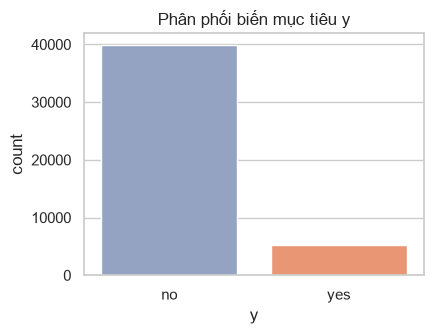

In [15]:
counts = df["y"].value_counts()
print(counts, "\nTỷ lệ đồng ý:", round(counts["yes"]/len(df)*100, 2), "%")
print("Accuracy nếu luôn đoán 'no':", round(counts["no"]/len(df)*100, 2), "%")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(data=df, x="y", ax=ax, palette=["#8da0cb", "#fc8d62"])
ax.set_title("Phân phối biến mục tiêu y"); plt.tight_layout()
plt.savefig("figs/01_target.png", dpi=150); plt.show()

**Nhận xét quan trọng:** dữ liệu **mất cân bằng** (~11,7% `yes`). Một mô hình ngu ngốc luôn đoán "no" đã đạt ~88,3% accuracy. Vì vậy **Accuracy không đủ tin cậy**; ta sẽ ưu tiên Recall, F1 và ROC-AUC.

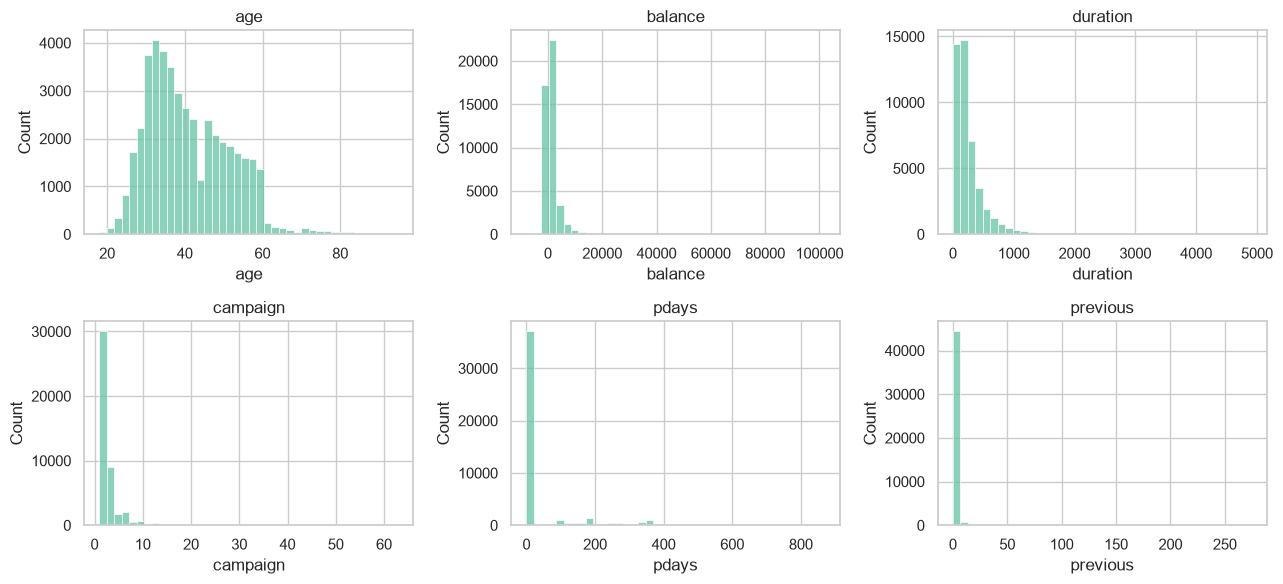

In [16]:
num_cols = ["age", "balance", "duration", "campaign", "pdays", "previous"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=40, ax=ax, color="#66c2a5"); ax.set_title(c)
plt.tight_layout(); plt.savefig("figs/02_numeric_hist.png", dpi=150); plt.show()

`balance`, `campaign`, `pdays`, `previous` lệch phải mạnh và có outlier lớn (ví dụ balance tối đa 102.127). Các mô hình cây không nhạy với outlier; với Logistic Regression ta sẽ chuẩn hóa và xử lý lệch bằng log.

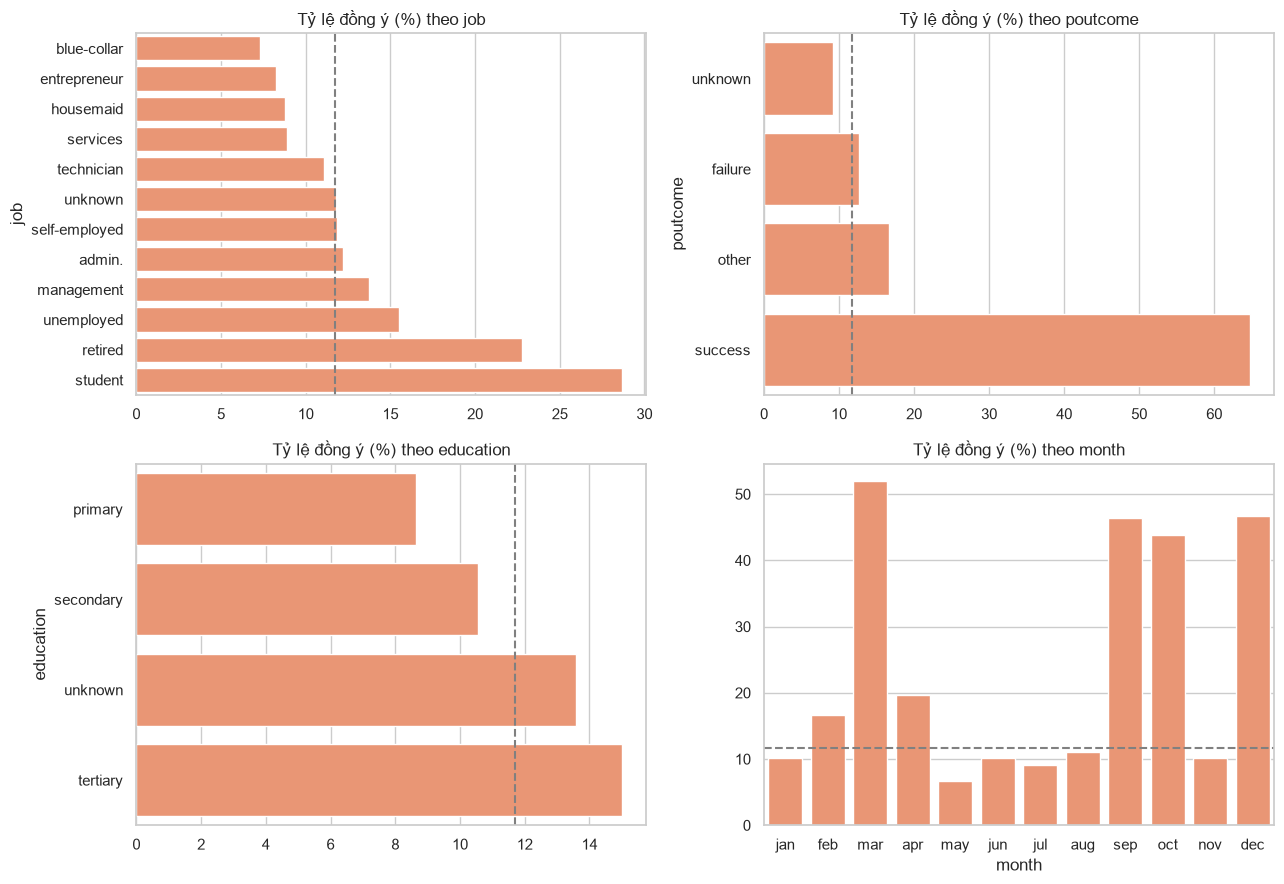

In [17]:
def rate_plot(col, ax, order=None):
    r = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean()*100)
    r = r.reindex(order) if order else r.sort_values()
    sns.barplot(x=r.values, y=r.index, ax=ax, color="#fc8d62") if order is None else sns.barplot(x=r.index, y=r.values, ax=ax, color="#fc8d62")
    ax.set_title(f"Tỷ lệ đồng ý (%) theo {col}"); ax.axvline(11.7, color="gray", ls="--") if order is None else ax.axhline(11.7, color="gray", ls="--")

months = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
rate_plot("job", axes[0,0]); rate_plot("poutcome", axes[0,1]); rate_plot("education", axes[1,0])
rate_plot("month", axes[1,1], order=months)
plt.tight_layout(); plt.savefig("figs/03_rate_by_cat.png", dpi=150); plt.show()

**Quan sát:** nhóm *student*, *retired*; khách từng đồng ý chiến dịch trước (`poutcome = success`); và các tháng 3, 9, 10, 12 có tỷ lệ đồng ý cao rõ rệt so với mức trung bình (đường nét đứt). Các tháng có nhiều cuộc gọi như tháng 5 lại có tỷ lệ thấp.

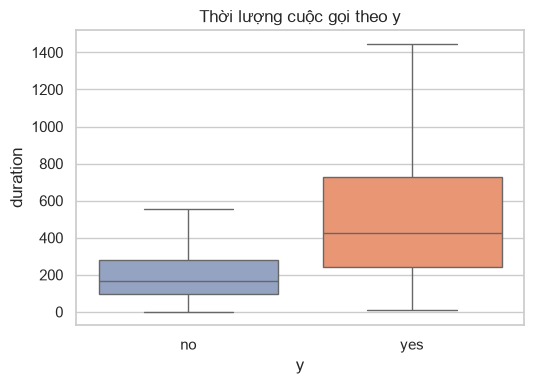

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.boxplot(data=df, x="y", y="duration", showfliers=False, ax=ax, palette=["#8da0cb", "#fc8d62"])
ax.set_title("Thời lượng cuộc gọi theo y"); plt.tight_layout()
plt.savefig("figs/04_duration.png", dpi=150); plt.show()

## 3. Tiền xử lý dữ liệu

**Quyết định quan trọng – loại bỏ `duration` (rò rỉ dữ liệu / data leakage):** thời lượng cuộc gọi chỉ biết *sau khi* cuộc gọi kết thúc, và cuộc gọi dài thường vì khách đã quan tâm. Tài liệu UCI cũng khuyến cáo bỏ cột này nếu muốn mô hình dự đoán thực tế *trước khi gọi*. Phần 7 sẽ cho thấy chênh lệch khi giữ lại để minh họa.

Các bước còn lại:
- Mã hóa `y`: yes → 1, no → 0.
- Tạo đặc trưng `contacted_before` từ `pdays` (≠ -1) và `log_balance` (giảm lệch).
- Giữ `"unknown"` như một nhóm riêng (vì chính việc không biết cũng mang thông tin, ví dụ `poutcome`).
- Numeric → `StandardScaler`; categorical → `OneHotEncoder`, gói trong `Pipeline` + `ColumnTransformer` để **tránh rò rỉ** khi cross-validation.
- Chia train/test 80/20 có `stratify=y` để giữ nguyên tỷ lệ lớp.

In [19]:
data = df.copy()
data["y"] = (data["y"] == "yes").astype(int)
data["contacted_before"] = (data["pdays"] != -1).astype(int)
data["log_balance"] = np.sign(data["balance"]) * np.log1p(data["balance"].abs())
data["pdays"] = data["pdays"].replace(-1, 0)           # chưa liên hệ -> 0 (đã có cờ contacted_before)

X = data.drop(columns=["y", "duration", "balance"])
y = data["y"]

num_features = ["age", "log_balance", "day", "campaign", "pdays", "previous", "contacted_before"]
cat_features = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Tỷ lệ yes – train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

def make_pre(scale=True):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)])

Train: (36168, 16) | Test: (9043, 16)
Tỷ lệ yes – train: 0.117 | test: 0.117


## 4. Huấn luyện và so sánh 4 mô hình bằng Cross-Validation
Dùng `class_weight="balanced"` để xử lý mất cân bằng lớp. Đánh giá bằng Stratified 5-Fold CV **chỉ trên tập train** (tập test giữ nguyên đến bước cuối).

In [ ]:
models = {
    "Logistic Regression": Pipeline([("pre", make_pre()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Decision Tree":       Pipeline([("pre", make_pre(False)), ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random Forest":       Pipeline([("pre", make_pre(False)), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))]),
    "Hist Gradient Boosting": Pipeline([("pre", make_pre(False)), ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["roc_auc", "f1", "recall", "precision", "accuracy"]

rows = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Mô hình": name, **{k: s[f"test_{k}"].mean() for k in scoring}, "AUC std": s["test_roc_auc"].std()})
cv_df = pd.DataFrame(rows).set_index("Mô hình").round(4)
cv_df

## 5. Tối ưu siêu tham số (Grid Search) cho mô hình tốt nhất
Dựa trên kết quả CV, ta tinh chỉnh mô hình boosting bằng `GridSearchCV` với thước đo ROC-AUC.

In [ ]:
best_name = cv_df["roc_auc"].idxmax()
print("Mô hình tốt nhất theo CV AUC:", best_name)

grid = GridSearchCV(
    models["Hist Gradient Boosting"],
    param_grid={"clf__learning_rate": [0.03, 0.06, 0.1],
                "clf__max_depth": [3, 5, None],
                "clf__min_samples_leaf": [20, 50],
                "clf__l2_regularization": [0.0, 1.0]},
    scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print("Best CV AUC: %.4f" % grid.best_score_)

## 6. Đánh giá cuối cùng trên tập test

In [ ]:
final_models = {
    "Logistic Regression": models["Logistic Regression"],
    "Decision Tree": models["Decision Tree"],
    "Random Forest": models["Random Forest"],
    "HGB (đã tune)": grid.best_estimator_,
}
res, probas = [], {}
for name, m in final_models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]; pred = (p >= 0.5).astype(int)
    probas[name] = p
    res.append({"Mô hình": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p)})
test_df = pd.DataFrame(res).set_index("Mô hình").round(4)
test_df

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test,p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, label=name)
axes[0].plot([0,1],[0,1],"k--"); axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Đường ROC"); axes[0].legend()
axes[1].axhline(y_test.mean(), color="k", ls="--"); axes[1].set(xlabel="Recall", ylabel="Precision", title="Đường Precision–Recall"); axes[1].legend()
plt.tight_layout(); plt.savefig("figs/05_roc_pr.png", dpi=150); plt.show()

In [ ]:
best = final_models["HGB (đã tune)"]
pred = (probas["HGB (đã tune)"] >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=["no", "yes"]))
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["no", "yes"], yticklabels=["no", "yes"])
ax.set(xlabel="Dự đoán", ylabel="Thực tế", title="Confusion Matrix – HGB (ngưỡng 0.5)")
plt.tight_layout(); plt.savefig("figs/06_confusion.png", dpi=150); plt.show()

**Nhận xét:** với `class_weight="balanced"`, mô hình bắt được phần lớn khách thực sự đồng ý (Recall cao) nhưng đổi lại Precision thấp, nghĩa là gọi nhầm nhiều khách. Đây là sự đánh đổi Precision–Recall; ngưỡng 0.5 không nhất thiết là lựa chọn tốt nhất về mặt kinh doanh.

## 7. Tối ưu ngưỡng và giá trị kinh doanh
Thay vì cố định 0.5, ta xem hiệu quả khi chỉ gọi top-k% khách có xác suất cao nhất (**lift / gain**), và tìm ngưỡng cho F1 tốt nhất.

In [ ]:
p = probas["HGB (đã tune)"]
ths = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_test, (p >= t).astype(int)) for t in ths]
t_best = ths[int(np.argmax(f1s))]
pred_t = (p >= t_best).astype(int)
print(f"Ngưỡng tối ưu F1: {t_best:.2f} | F1={max(f1s):.3f} | Precision={precision_score(y_test,pred_t):.3f} | Recall={recall_score(y_test,pred_t):.3f}")

order = np.argsort(-p); y_sorted = y_test.values[order]; base = y_test.mean()
rows = []
for k in [0.05, 0.10, 0.20, 0.30, 0.50]:
    n = int(len(p)*k); captured = y_sorted[:n].sum()/y_test.sum(); prec = y_sorted[:n].mean()
    rows.append({"Gọi top": f"{int(k*100)}%", "Tỷ lệ đồng ý trong nhóm": round(prec, 3), "Lift": round(prec/base, 2), "% khách đồng ý bắt được": round(captured, 3)})
gain_df = pd.DataFrame(rows); gain_df

In [ ]:
cum = np.cumsum(y_sorted)/y_sorted.sum(); x = np.arange(1, len(p)+1)/len(p)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(x, cum, label="Mô hình HGB"); ax.plot([0,1],[0,1],"k--", label="Gọi ngẫu nhiên")
ax.set(xlabel="Tỷ lệ khách được gọi (xếp theo xác suất)", ylabel="Tỷ lệ khách đồng ý bắt được", title="Đường Gain"); ax.legend()
plt.tight_layout(); plt.savefig("figs/07_gain.png", dpi=150); plt.show()

## 8. Yếu tố nào ảnh hưởng nhiều nhất? (Permutation Importance)
Hoán vị từng đặc trưng gốc trên tập test và đo mức giảm ROC-AUC. Cách này gộp các cột one-hot về đúng đặc trưng ban đầu nên dễ diễn giải.

In [ ]:
pi = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.tail(12).plot.barh(ax=ax, color="#66c2a5"); ax.set(title="Mức giảm ROC-AUC khi hoán vị đặc trưng", xlabel="Giảm AUC")
plt.tight_layout(); plt.savefig("figs/08_importance.png", dpi=150); plt.show()
imp.sort_values(ascending=False).head(8).round(4)

## 9. Thử nghiệm: nếu giữ lại `duration` thì sao?
Chỉ để minh họa vì sao phải loại bỏ. Mô hình này **không dùng được thực tế** vì chưa gọi thì chưa biết thời lượng.

In [ ]:
X2 = data.drop(columns=["y", "balance"])
Xtr2, Xte2, ytr2, yte2 = train_test_split(X2, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
num2 = num_features + ["duration"]
pre2 = ColumnTransformer([("num", "passthrough", num2), ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)])
m2 = Pipeline([("pre", pre2), ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE, **{k.replace("clf__",""): v for k, v in grid.best_params_.items()}))])
m2.fit(Xtr2, ytr2)
auc_leak = roc_auc_score(yte2, m2.predict_proba(Xte2)[:, 1])
auc_ok = roc_auc_score(y_test, probas["HGB (đã tune)"])
print(f"ROC-AUC không có duration: {auc_ok:.3f} | có duration: {auc_leak:.3f}")

## 10. Kết luận và đề xuất
- Dữ liệu mất cân bằng nên dùng Recall/F1/ROC-AUC thay vì chỉ Accuracy.
- Các mô hình cây tăng cường (boosting) và Random Forest vượt Logistic Regression và Decision Tree đơn lẻ.
- Nên dùng mô hình để **xếp hạng khách hàng** và ưu tiên gọi nhóm điểm cao, thay vì gọi đại trà.
- Tháng thực hiện, loại liên hệ (contact), kết quả chiến dịch trước (poutcome) và ngày trong tháng là các yếu tố ảnh hưởng nhất.